In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from typing import Dict, List, Tuple, Optional
import h5py
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from tqdm import tqdm
from mode_solver import find_guided_modes
from tm_sampler import sample_tm_perturbed_mmf
from utils import (
    plot_results as utils_plot_results,
    plot_training_intensity_example as utils_plot_training_intensity_example,
    plot_training_history as utils_plot_training_history,
    ZoomFFT2D_Optimizable,
    ZernikeAberrationLayer
)
from metrics_losses import (
    calculate_phase_aligned_frobenius_norm,
    calculate_phase_aligned_tm_error,
    evaluate_reconstruction as metrics_evaluate_reconstruction
)


## Real Data Loading Functions

Functions to load and process real MMF measurement data from H5 files.


In [2]:
def load_real_mmf_data(h5_file_path: str, experiment_group: str, train_test_split_ratio: float = 0.8, random_seed: int = 42, im_factor: float = 1.0):
    """
    Load real MMF measurement data from an H5 file.
    
    Args:
        h5_file_path: Path to the H5 file containing the measurements
        experiment_group: Name of the group/experiment to load (e.g., 'experiment_1', 'group_0')
        train_test_split_ratio: Ratio of data to use for training (default 0.8 = 80% train, 20% test)
        random_seed: Random seed for train/test split reproducibility
    
    Returns:
        Tuple of (train_data, test_data) where each is a dict with:
            - 'slm_patterns': SLM phase masks (N, H, W)
            - 'intensity_image': Image plane intensities (N, H, W)
            - 'intensity_fourier': Fourier plane intensities (N, H, W)
            - 'intensity_targets': Combined intensities (N, 2, H, W) where [:, 0] = image, [:, 1] = fourier
    """
    print(f"Loading data from {h5_file_path}, group: {experiment_group}")
    
    with h5py.File(h5_file_path, 'r') as f:
        if experiment_group not in f.keys():
            raise ValueError(f"Group '{experiment_group}' not found in H5 file. Available groups: {list(f.keys())}")
        
        group = f[experiment_group]
        
        # Try different possible dataset names
        slm_key = None
        img_key = None
        fourier_key = None
        
        for key in group.keys():
            key_lower = key.lower()
            if 'slm' in key_lower or ('phase' in key_lower or 'mask' in key_lower):
                slm_key = key
            elif 'image' in key_lower and 'transmission' in key_lower:
                img_key = key
            elif 'fourier' in key_lower and 'transmission' in key_lower:
                fourier_key = key
        
        # Fallback to default names if not found
        if slm_key is None:
            slm_key = 'slm_phase_mask'
        if img_key is None:
            img_key = 'transmission_image_intensity'
        if fourier_key is None:
            fourier_key = 'transmission_fourier_intensity'
        
        # Load the three datasets
        slm_phase = group[slm_key][:]  # (N, H, W)
        slm_phase = np.flip(slm_phase, axis=(-2,-1))  # flip because of the 4F system
        intensity_image = group[img_key][:]  # (N, H, W)
        intensity_image = np.flip(intensity_image, axis=(-2,-1))  # flip because of the 4F system and BS
        intensity_fourier = group[fourier_key][:]  # (N, H, W)
        # intensity_fourier = np.flip(intensity_fourier, axis=(-2))  # flip because of the 4F system and BS
        
        print(f"Using dataset keys: {slm_key}, {img_key}, {fourier_key}")
        
        print(f"Loaded data shapes:")
        print(f"  SLM phase masks: {slm_phase.shape}, dtype: {slm_phase.dtype}")
        print(f"  Image intensities: {intensity_image.shape}, dtype: {intensity_image.dtype}")
        print(f"  Fourier intensities: {intensity_fourier.shape}, dtype: {intensity_fourier.dtype}")
        
        # Convert uint8 phase masks to phase values: 0-255 -> 0 to 2π*255/256
        # Formula: phase = uint8_value * (2π * 255/256) / 255 = uint8_value * 2π / 256
        if slm_phase.dtype == np.uint8 or slm_phase.dtype == 'uint8':
            print("Converting uint8 phase masks to phase values (0-255 -> 0 to 2π*255/256)...")
            slm_phase = slm_phase.astype(np.float32) * 2 * np.pi / 256.0
            print(f"slm_phase max: {slm_phase.max()} | slm_phase min: {slm_phase.min()}")
        elif slm_phase.max() <= 1.0 and slm_phase.min() >= 0.0:
            # If already normalized to [0, 1], scale to [0, 2π]
            print("Scaling phase masks from [0, 1] to [0, 2π]...")
            slm_phase = slm_phase.astype(np.float32) * 2 * np.pi
        else:
            # Assume already in phase range [0, 2π]
            slm_phase = slm_phase.astype(np.float32)
        
        # Combine intensities: (N, 2, H, W) where [:, 0] = image, [:, 1] = fourier
        intensity_targets = np.stack([intensity_image, intensity_fourier], axis=1)  # (N, 2, H, W)
        
        # Convert to torch tensors
        slm_phase_tensor = torch.from_numpy(slm_phase).float()
        intensity_targets_tensor = torch.from_numpy(intensity_targets).float()
        intensity_targets_tensor[:,0] = intensity_targets_tensor[:,0] * im_factor
        # Split into train and test
        num_samples = slm_phase_tensor.shape[0]
        indices = np.arange(num_samples)
        train_indices, test_indices = train_test_split(
            indices, 
            test_size=1 - train_test_split_ratio, 
            random_state=random_seed
        )
        
        train_data = {
            'slm_patterns': slm_phase_tensor[train_indices],
            'intensity_image': torch.from_numpy(intensity_image[train_indices]).float(),
            'intensity_fourier': torch.from_numpy(intensity_fourier[train_indices]).float(),
            'intensity_targets': intensity_targets_tensor[train_indices]
        }
        
        test_data = {
            'slm_patterns': slm_phase_tensor[test_indices],
            'intensity_image': torch.from_numpy(intensity_image[test_indices]).float(),
            'intensity_fourier': torch.from_numpy(intensity_fourier[test_indices]).float(),
            'intensity_targets': intensity_targets_tensor[test_indices]
        }
        
        print(f"\nData split:")
        print(f"  Training samples: {len(train_indices)} ({len(train_indices)/num_samples*100:.1f}%)")
        print(f"  Test samples: {len(test_indices)} ({len(test_indices)/num_samples*100:.1f}%)")
        
        return train_data, test_data


def list_h5_experiments(h5_file_path: str):
    """
    List all available experiment groups in an H5 file.
    
    Args:
        h5_file_path: Path to the H5 file
    
    Returns:
        List of group names
    """
    with h5py.File(h5_file_path, 'r') as f:
        groups = list(f.keys())
        print(f"Available experiment groups in {h5_file_path}:")
        for i, group in enumerate(groups):
            print(f"  {i}: {group}")
        return groups


In [ ]:
from TM_retrieve import TMMeasurementSystem
from metrics_losses import PearsonCorrelationLoss
def optimize_tm_slm(
    tm_system: TMMeasurementSystem,
    slm_patterns: torch.Tensor,
    intensity_targets: torch.Tensor,
    num_epochs: int = 100,
    learning_rate: float = 0.01,
    batch_size: int = 32,
    planes: str = 'both',
    optimize_aberrations: bool = True,
    test_data: Optional[Dict] = None,
    use_exposure_normalization: bool = False
) -> Dict:
    """
    Optimize TM and Aberrations using Adam optimizer.
    
    Uses the TMMeasurementSystem's internal nn.Parameters directly:
    - optimized_tm: Transmission matrix
    - zernike_*: Zernike aberration coefficients (4 sets)
    - zoomfft_*_params: ZoomFFT parameters (3 sets)
    - slm_complex_amplitude: Complex amplitude at SLM plane
    
    Args:
        tm_system: TMMeasurementSystem nn.Module with learnable parameters
        slm_patterns: SLM phase patterns (N, H, W)
        intensity_targets: Target intensities (N, 2, H, W) where [:, 0] = image, [:, 1] = fourier
        num_epochs: Number of training epochs
        learning_rate: Learning rate for Adam optimizer
        batch_size: Batch size for training
        planes: 'both', 'image', or 'fourier' - which plane(s) to optimize on
        optimize_aberrations: If True, optimize aberrations (ZoomFFT and Zernike parameters)
        test_data: Optional dict with test data to evaluate test loss after each epoch
        use_exposure_normalization: If True, apply exposure time normalization (for real lab data).
                                   Calculates optimal scalar a = sum(I_hat * I) / sum(I_hat^2) 
                                   separately for each plane. Set to False for simulated data.
    
    Returns:
        Dict containing optimization history
    """
    print(f"Starting Adam Optimization using TMMeasurementSystem internal parameters.")
    print(f"Optimize Aberrations: {optimize_aberrations}")
    
    # --- 1. Configure which parameters to optimize ---
    # TM is always optimized (use _optimized_tm_param, not the property)
    tm_system._optimized_tm_param.requires_grad_(True)
    tm_system.slm_complex_amplitude.requires_grad_(True)
    
    # Aberration parameters are controlled by the flag
    for param in [tm_system.zernike_before_ft, tm_system.zernike_after_ft,
                  tm_system.zernike_image_plane, tm_system.zernike_fourier_domain]:
        param.requires_grad_(optimize_aberrations)
    
    for param_dict in [tm_system.zoomfft_slm_params, tm_system.zoomfft_out_fwd_params,
                       tm_system.zoomfft_out_inv_params]:
        for param in param_dict.values():
            param.requires_grad_(optimize_aberrations)

    # --- 2. Setup Optimizer using module's parameters ---
    optimizer = optim.Adam(tm_system.parameters(), lr=learning_rate)
    num_trainable_params = sum(p.numel() for p in tm_system.parameters() if p.requires_grad)
    print(f"Number of parameters to be optimized: {num_trainable_params}")
    criterion = nn.L1Loss()
    criterion = PearsonCorrelationLoss(dim=(0,2,3), center=False)
    
    # Ensure planes is a string (defensive check)
    if not isinstance(planes, str):
        raise TypeError(f"planes must be a string, got {type(planes)}: {planes}")
    planes_l = planes.lower()
    num_measurements = slm_patterns.shape[0]
    num_batches = (num_measurements + batch_size - 1) // batch_size
    history = {
        'epoch_losses': [],
        'test_losses': [],
        'tm_error': [],
        'tm_norm': [],
        'tm_frobenius_error_aligned': []
    }

    print(f"Measurements: {num_measurements} | Batches/Epoch: {num_batches} | LR: {learning_rate}")

    # --- 3. Training Loop ---
    if not isinstance(num_epochs, int):
        num_epochs = int(num_epochs)
    
    for epoch in range(num_epochs):
        total_epoch_loss = 0.0

        # Shuffle data
        indices = torch.randperm(num_measurements)

        # Loop over batches
        for i in range(num_batches):
            optimizer.zero_grad()
            start = i * batch_size
            end = min(start + batch_size, num_measurements)
            batch_idx = indices[start:end]
            
            # Forward pass using internal parameters (use_internal_params=True by default)
            pred_intensity = tm_system.forward_model_slm(slm_patterns[batch_idx])

            # Exposure time normalization: calculate optimal scalar a = sum(I_hat * I) / sum(I_hat^2)
            if use_exposure_normalization:
                with torch.no_grad():
                    numerator = torch.sum(pred_intensity * intensity_targets[batch_idx], dim=(-1,-2), keepdim=True)
                    denominator = torch.sum(pred_intensity ** 2, dim=(-1,-2), keepdim=True)
                    scale = (numerator / (denominator)).mean(dim=0, keepdim=True).detach()
            else:
                scale = 1.0

            # Apply scale and select planes
            pred_normalized = pred_intensity * scale
            if planes_l == 'image':
                pred_normalized = pred_normalized[:, 0:1]
                target_normalized = intensity_targets[batch_idx][:, 0:1]
            elif planes_l == 'fourier':
                pred_normalized = pred_normalized[:, 1:2]
                target_normalized = intensity_targets[batch_idx][:, 1:2]
            else:
                target_normalized = intensity_targets[batch_idx]
            
            # Print relative power on first batch of each epoch
            if i == 0:
                with torch.no_grad():
                    pred_power = torch.sum(pred_intensity, dim=(-1,-2)).mean(dim=0)
                    rel_power = pred_power[0] / pred_power[1] * (tm_system.dx['im']/tm_system.dx['four'])**2
                print(f"rel_power: {rel_power}")
                
            # Loss (Amplitude)
            pred_amp = torch.sqrt(pred_normalized)
            target_amp = torch.sqrt(target_normalized)
            # Normalization (Crucial for stability)
            norm_factor = torch.mean(target_amp).detach()
            loss = criterion(pred_amp / norm_factor, target_amp / norm_factor)
            
            # Backward and step
            loss.backward()
            optimizer.step()
            
            # Track loss for reporting
            total_epoch_loss += loss.item()
        
        # Logging
        avg_loss = total_epoch_loss / num_batches
        
        # Calculate test loss if test data is provided
        test_loss = None
        if test_data is not None:
            with torch.no_grad():
                test_slm = test_data['slm_patterns'].to(tm_system.device)
                test_targets = test_data['intensity_targets'].to(tm_system.device)
                
                # Forward pass using internal parameters
                test_pred = tm_system.forward_model_slm(test_slm)
                
                # Select planes and apply exposure time normalization (if enabled)
                if use_exposure_normalization:
                    if planes_l == 'image':
                        test_pred_sel = test_pred[:, 0:1]
                        test_target_sel = test_targets[:, 0:1]
                        numerator_test = torch.sum(test_pred_sel * test_target_sel)
                        denominator_test = torch.sum(test_pred_sel ** 2)
                        scale_test = (numerator_test / (denominator_test)).detach()
                        test_pred_normalized = test_pred_sel * scale_test
                        test_target_normalized = test_target_sel
                    elif planes_l == 'fourier':
                        test_pred_sel = test_pred[:, 1:2]
                        test_target_sel = test_targets[:, 1:2]
                        numerator_test = torch.sum(test_pred_sel * test_target_sel)
                        denominator_test = torch.sum(test_pred_sel ** 2)
                        scale_test = (numerator_test / (denominator_test)).detach()
                        test_pred_normalized = test_pred_sel * scale_test
                        test_target_normalized = test_target_sel
                    else:
                        # Both planes: calculate scalars separately
                        test_pred_image = test_pred[:, 0:1]
                        test_target_image = test_targets[:, 0:1]
                        numerator_img = torch.sum(test_pred_image * test_target_image)
                        denominator_img = torch.sum(test_pred_image ** 2)
                        scale_img = (numerator_img / (denominator_img)).detach()
                        test_pred_fourier = test_pred[:, 1:2]
                        test_target_fourier = test_targets[:, 1:2]
                        numerator_fourier = torch.sum(test_pred_fourier * test_target_fourier)
                        denominator_fourier = torch.sum(test_pred_fourier ** 2)
                        scale_fourier = (numerator_fourier / (denominator_fourier)).detach()
                        
                        test_pred_normalized = torch.cat([test_pred_image * scale_img, test_pred_fourier * scale_fourier], dim=1)
                        test_target_normalized = test_targets
                else:
                    if planes_l == 'image':
                        test_pred_normalized = test_pred[:, 0:1]
                        test_target_normalized = test_targets[:, 0:1]
                    elif planes_l == 'fourier':
                        test_pred_normalized = test_pred[:, 1:2]
                        test_target_normalized = test_targets[:, 1:2]
                    else:
                        test_pred_normalized = test_pred
                        test_target_normalized = test_targets
                
                # Calculate test loss
                test_pred_amp = torch.sqrt(test_pred_normalized)
                test_target_amp = torch.sqrt(test_target_normalized)
                norm_factor_test = torch.mean(test_target_amp).detach()
                test_loss = criterion(test_pred_amp / norm_factor_test, test_target_amp / norm_factor_test).item()
        
        # Calculate TM metrics
        with torch.no_grad():
            if hasattr(tm_system, 'real_tm_tensor') and tm_system.real_tm_tensor is not None:
                tm_error, _ = calculate_phase_aligned_frobenius_norm(tm_system.real_tm_tensor, tm_system.optimized_tm)
            else:
                tm_error = 0.0
            tm_norm = torch.norm(tm_system.optimized_tm).item()
        
        history['epoch_losses'].append(avg_loss)
        if test_loss is not None:
            history['test_losses'].append(test_loss)
        history['tm_error'].append(tm_error)
        history['tm_norm'].append(tm_norm)
        history['tm_frobenius_error_aligned'].append(tm_error)
        
        # Print losses
        if test_loss is not None:
            print(f"Epoch {epoch+1}/{num_epochs}: Train Loss={avg_loss:.6f}, Test Loss={test_loss:.6f}, TM Norm={tm_norm:.6f}")
        else:
            print(f"Epoch {epoch+1}/{num_epochs}: Loss={avg_loss:.6f}, TM Error={tm_error:.4f}, TM Norm={tm_norm:.6f}")

    print("Optimization Completed.")
    return history

## System parameters
calculating the parameters suiteable to the lab optical setup

In [4]:
magnification = 50.0  # 50x objective
dx_cam = 3.45e-6  # camera pixel size
dx_im = {'tran': dx_cam/magnification, 'ref': dx_cam/magnification}
dx_four = {'tran': dx_cam, 'ref': dx_cam*(250.0/200.0)}
NA = 0.22  # numerical aperture of the MMF
obj_f = 200e-3/magnification  # objective focal length
et_ratio = 120.0/150.0  # exposure time ratio
bs_split = 0.47736  # beam splitter split ratio
margin = 1.1
four_range = margin*NA*obj_f
core_radius = 25e-6  # core radius of the MMF
im_range = margin*core_radius
dx_SLM = 8e-6*(150.0/400.0)  # SLM pixel size after 4F system
N_pix = {}
for side in ['tran', 'ref']:
    N_pix[side] = {}
    N_pix[side]['im'] = round(im_range/dx_im[side])
    N_pix[side]['four'] = round(four_range/dx_four[side])
N_pix['slm'] = 320
dx_final = {}  # pixels size after resize and cropping
for side in ['tran', 'ref']:
    dx_final[side] = {}
    dx_final[side]['im'] = dx_im[side]*N_pix[side]['im']/64.0
    dx_final[side]['four'] = dx_four[side]*N_pix[side]['four']/64.0
    dx_final[side]['slm'] = dx_SLM*N_pix['slm']/64.0
    
tran_im_factor = magnification**2*bs_split/(1-bs_split)*et_ratio
# lab data
h5_file_path = "measurement_sampler_data3.h5"  # Update with your H5 file path
experiment_group = "experiment_1"  # Update with the experiment group name
train_test_ratio = 0.8
train_data, test_data = load_real_mmf_data(
    h5_file_path=h5_file_path,
    experiment_group=experiment_group,
    train_test_split_ratio=train_test_ratio,
    random_seed=42,
    im_factor=tran_im_factor
)

# System parameters
wavelength = 632.8e-9
core_index = 1.457
NA = 0.2243  # measured NA in the lab
core_radius = 25.53e-6  # 25.53 micron core radius measured in the lab
cladding_index = np.sqrt(core_index**2 - NA**2)
N_0 = 128
f = 200e-3 # focal length of the lens
mult_factor = {
    'tran': dx_final['tran']['im']**2/(wavelength*obj_f),
    'slm': dx_final['tran']['slm']**2/(wavelength*obj_f)
}

# Define fiber parameters
fiber_params = {
    'a': core_radius,  # 25 micron core radius
    'n1': core_index,  # Core refractive index
    'n0': cladding_index,  # Cladding refractive index
    'wavelength': wavelength  # 632.8 nm wavelength
}

# Define grid parameters
range_im = (N_0/2)*dx_final['tran']['im']
grid_params = {
    'x_range': (-range_im, range_im),
    'y_range': (-range_im, range_im),
    'nx': N_0,
    'ny': N_0
}

# Define ZoomFFT parameters
a_param = {
    'slm': 2*np.pi*dx_final['tran']['slm']*dx_final['tran']['im']/(wavelength*obj_f),
    'tran': 2*np.pi*dx_final['tran']['im']*dx_final['tran']['four']/(wavelength*obj_f)
}

zoomfft_params = {}
for side in ['slm', 'tran']:
    zoomfft_params[side] = {
        'a_init': a_param[side],
        'n0_init': (N_0 - 1) / 2,
        'm0_init': (N_0 - 1) / 2,
        'k0_init': (N_0 - 1) / 2,
        'l0_init': (N_0 - 1) / 2
    }

# Initialize the system
print("Initializing TM Measurement System...")
tm_system = TMMeasurementSystem(
    fiber_params, grid_params, 
    device='cuda', 
    mult_factor=mult_factor,
    zoomfft_params=zoomfft_params,
    zernike_n_modes=8,
    dx=dx_final['tran']
)


Loading data from measurement_sampler_data3.h5, group: experiment_1
Using dataset keys: PhaseMask, transmission_image, transmission_fourier
Loaded data shapes:
  SLM phase masks: (6000, 128, 128), dtype: uint8
  Image intensities: (6000, 128, 128), dtype: uint8
  Fourier intensities: (6000, 128, 128), dtype: uint8
Converting uint8 phase masks to phase values (0-255 -> 0 to 2π*255/256)...
slm_phase max: 6.258641719818115 | slm_phase min: 0.0

Data split:
  Training samples: 4800 (80.0%)
  Test samples: 1200 (20.0%)
Initializing TM Measurement System...
Calculating guided modes...
Fiber V-number: 56.858
Fiber is multi-mode.
Loading mode_fields from mode_fields_baa2bed8.pt...
Successfully loaded mode_fields with shape: torch.Size([1, 2, 128, 128, 1624])
Sampling transmission matrices for 1624 modes...
System initialized with 1624 guided modes
Grid size: 128 x 128
Aberration models initialized: ZoomFFT and 8 Zernike modes


In [5]:
# ===== SLM Pattern Optimization =====
# Set these flags to test different configurations:
simulated_data = False
if simulated_data:
    use_aberrations_in_target = True  # If True, targets have aberrations; if False, no aberrations
    optimize_aberrations = True       # If True, optimize TM+aberrations; if False, optimize TM only

    print("\n" + "="*60)
    print(f"SLM Pattern Optimization Mode")
    print(f"  Target aberrations: {use_aberrations_in_target}")
    print(f"  Optimize aberrations: {optimize_aberrations}")
    print("="*60)

    # Sample SLM measurements
    print("\nSampling SLM measurements...")
    slm_patterns, intensity_measurements = tm_system.sample_measurements_slm(
        num_measurements=4000, use_aberrations=use_aberrations_in_target)

    # Optimize TM (and optionally aberrations)
    print("\nOptimizing transmission matrix...")
    import time
    start_time = time.time()
    history = optimize_tm_slm(
        tm_system=tm_system,
        slm_patterns=slm_patterns,
        intensity_targets=intensity_measurements,
        num_epochs=50,
        learning_rate=0.005,
        batch_size=512,
        planes='both',
        optimize_aberrations=optimize_aberrations,
        use_exposure_normalization=False
    )
    end_time = time.time()
    print(f"Optimization time: {end_time - start_time:.2f} seconds")


In [6]:
if simulated_data:
    # Evaluate results
    print("\nEvaluating reconstruction quality...")
    evaluation_results = tm_system.evaluate_reconstruction()

    # Print results
    print(f"\nReconstruction Results:")
    print(f"TM Frobenius Error (Phase-Aligned, Normalized): {evaluation_results['tm_frobenius_error_aligned_normalized']:.6f}")
    print(f"Optimal Phase: {evaluation_results['optimal_phase_degrees']:.2f}° ({evaluation_results['optimal_phase_radians']:.4f} rad)")
    print(f"Intensity Mean Error (Normalized): {evaluation_results['intensity_mean_error_normalized']:.6f}")

    # Plot training history
    print("\nPlotting training history...")
    tm_system.plot_training_history(history)

    # Plot evaluation results
    print("\nPlotting evaluation results...")
    tm_system.plot_results(evaluation_results)

## Real MMF Data Processing

Load real measurement data from H5 files and optimize TM.


In [7]:
# ===== Real MMF Data Processing =====
# Configuration
h5_file_path = "measurement_sampler_data3.h5"  # Update with your H5 file path
experiment_group = "experiment_0"  # Update with the experiment group name
train_test_ratio = 0.8  # 80% training, 20% testing

# List available experiments (uncomment to see available groups)
# list_h5_experiments(h5_file_path)

# Load real data
print("\n" + "="*60)
print("Loading Real MMF Measurement Data")
print("="*60)
train_data, test_data = load_real_mmf_data(
    h5_file_path=h5_file_path,
    experiment_group=experiment_group,
    train_test_split_ratio=train_test_ratio,
    random_seed=42,
    im_factor=tran_im_factor
)

# Move data to appropriate device
device = 'cuda' if torch.cuda.is_available() else 'cpu'
train_data['slm_patterns'] = train_data['slm_patterns'].to(device)
train_data['intensity_targets'] = train_data['intensity_targets'].to(device)
test_data['slm_patterns'] = test_data['slm_patterns'].to(device)
test_data['intensity_targets'] = test_data['intensity_targets'].to(device)

# Note: Ensure SLM phase patterns are in range [0, 2π]
# If your data is in a different range, normalize it here:
# train_data['slm_patterns'] = (train_data['slm_patterns'] - train_data['slm_patterns'].min()) / (train_data['slm_patterns'].max() - train_data['slm_patterns'].min()) * 2 * np.pi
# test_data['slm_patterns'] = (test_data['slm_patterns'] - test_data['slm_patterns'].min()) / (test_data['slm_patterns'].max() - test_data['slm_patterns'].min()) * 2 * np.pi

print(f"\nData moved to device: {device}")
print(f"Training data shapes:")
print(f"  SLM patterns: {train_data['slm_patterns'].shape}")
print(f"  Intensity targets: {train_data['intensity_targets'].shape}")
print(f"Test data shapes:")
print(f"  SLM patterns: {test_data['slm_patterns'].shape}")
print(f"  Intensity targets: {test_data['intensity_targets'].shape}")
tot_power = torch.sum(train_data['intensity_targets'], dim=(-1,-2)).mean(dim=0)
print(f"Total power: {tot_power[0]/tot_power[1]*(dx_final['tran']['im']/dx_final['tran']['four'])**2}")


Loading Real MMF Measurement Data
Loading data from measurement_sampler_data3.h5, group: experiment_0
Using dataset keys: PhaseMask, transmission_image, transmission_fourier
Loaded data shapes:
  SLM phase masks: (6000, 128, 128), dtype: uint8
  Image intensities: (6000, 128, 128), dtype: uint8
  Fourier intensities: (6000, 128, 128), dtype: uint8
Converting uint8 phase masks to phase values (0-255 -> 0 to 2π*255/256)...
slm_phase max: 6.258641719818115 | slm_phase min: 0.0

Data split:
  Training samples: 4800 (80.0%)
  Test samples: 1200 (20.0%)

Data moved to device: cuda
Training data shapes:
  SLM patterns: torch.Size([4800, 128, 128])
  Intensity targets: torch.Size([4800, 2, 128, 128])
Test data shapes:
  SLM patterns: torch.Size([1200, 128, 128])
  Intensity targets: torch.Size([1200, 2, 128, 128])
Total power: 1.048471212387085


In [ ]:
# Initialize the system
tm_system_real = TMMeasurementSystem(
    fiber_params, grid_params, 
    device='cuda', 
    mult_factor=mult_factor,
    zoomfft_params=zoomfft_params,
    zernike_n_modes=8,
    lab_data=False,
    dx=dx_final['tran'],
    enforce_symmetric_tm=False
)
print("System initialized successfully!")

Calculating guided modes...
Fiber V-number: 56.858
Fiber is multi-mode.
Loading mode_fields from mode_fields_baa2bed8.pt...
Successfully loaded mode_fields with shape: torch.Size([1, 2, 128, 128, 1624])
Sampling transmission matrices for 1624 modes...
System initialized with 1624 guided modes
Grid size: 128 x 128
Aberration models initialized: ZoomFFT and 8 Zernike modes
System initialized successfully!


Scanning 1296 target points...
torch.Size([128, 128])


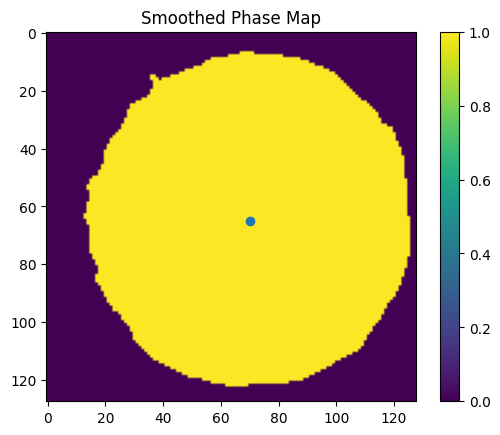

x_0, y_0: 70.25467724556765, 64.90743461651485
x_0_n, y_0_n: 1.1063728700089392, 1.0221643246695251


In [9]:
import torch
import torch.nn.functional as F
import numpy as np

def median_filter_pytorch(input_tensor, kernel_size):
    """
    Applies a 2D median filter to a PyTorch tensor (B, C, H, W).

    Args:
        input_tensor (torch.Tensor): Input tensor of shape (B, C, H, W).
        kernel_size (int): Size of the square median filter kernel (e.g., 3 for 3x3).

    Returns:
        torch.Tensor: Filtered tensor.
    """
    if kernel_size % 2 == 0:
        raise ValueError("Kernel size must be odd.")
    
    # Calculate padding to maintain original image size
    padding = kernel_size // 2
    
    # Unfold the input tensor into patches
    # The output shape of unfold is (B, C * kernel_size * kernel_size, H_out * W_out)
    unfolded = F.unfold(input_tensor, kernel_size=kernel_size, padding=padding, stride=1)
    
    # Reshape the unfolded tensor to easily calculate the median along the patch dimension
    # Shape becomes (B, C, kernel_size*kernel_size, H_out*W_out)
    # Then transpose to (B, C, H_out*W_out, kernel_size*kernel_size) to sort along the last dim
    unfolded = unfolded.view(input_tensor.shape[0], input_tensor.shape[1], kernel_size*kernel_size, -1).transpose(2, 3)

    # Calculate the median along the last dimension (the patch values)
    # torch.median returns a named tuple (values, indices), we only need the values
    median_values = torch.median(unfolded, dim=-1)[0]
    
    # Reshape back to the original image dimensions (B, C, H, W)
    output_tensor = median_values.view(input_tensor.shape[0], input_tensor.shape[1], input_tensor.shape[2], input_tensor.shape[3])
    
    return output_tensor

def get_aggregated_active_pupil(slm_phases, intensity_images, grid_step=3, percentile=95):
    """
    Recovers the full active pupil by aggregating correlation maps from multiple output targets.
    
    Args:
        slm_phases: (N, H_slm, W_slm) complex or phase tensor.
        intensity_images: (N, H_cam, W_cam) intensity tensor.
        grid_step: Stride for sampling target points in the output image (smaller = more detailed, slower).
        percentile: The top X% of pixels to keep from each individual map (e.g., 90 for top 10%).
    """
    N, H_slm, W_slm = slm_phases.shape
    _, H_cam, W_cam = intensity_images.shape
    device = slm_phases.device

    # 1. Pre-calculate SLM Phasors (do this once to save time)
    slm_phasors = torch.exp(1j * slm_phases)
    # Centering and Normalizing SLM data once
    phasors_centered = slm_phasors - slm_phasors.mean(dim=0, keepdim=True)
    # Normalizing by std dev is good, but for speed in a loop, simple centering is often enough.
    # If you want strict Pearson correlation, keep the normalization:
    phasors_std = torch.sqrt(torch.mean(torch.abs(phasors_centered)**2, dim=0, keepdim=True))
    phasors_norm = phasors_centered / phasors_std

    # Accumulator for the final map
    master_pupil_map = torch.zeros((H_slm, W_slm), device=device)
    
    # 2. Loop over a grid of target points in the camera image
    # We select points across the fiber face to capture all modes.
    # Assumes the fiber face is roughly centered or fills the frame.
    y_coords = range(10, H_cam - 10, grid_step)
    x_coords = range(10, W_cam - 10, grid_step)
    
    print(f"Scanning {len(y_coords)*len(x_coords)} target points...")

    for y in y_coords:
        for x in x_coords:
            # A. Get Target Signal (Single Pixel or Small ROI)
            # Using a 3x3 ROI averaging reduces camera read noise
            target_signal = intensity_images[:, y-1:y+2, x-1:x+2].mean(dim=(1, 2), keepdim=True)
            
            # Skip dark targets (areas outside the fiber face)
            if target_signal.mean() < intensity_images.mean() * 0.5:
                continue

            # B. Center and Normalize Target
            sig_centered = target_signal - target_signal.mean()
            sig_std = torch.sqrt(torch.mean(sig_centered**2)) + 1e-6
            sig_norm = (sig_centered / sig_std).to(phasors_norm.dtype) # Cast to complex

            # C. Fast Correlation (Matrix Mult)
            # (H*W, N) @ (N, 1) -> (H*W, 1)
            # Reshaping to 2D for fast matmul instead of einsum can be slightly faster in loops
            # But einsum is fine.
            raw_map = torch.einsum('nhw,ncd->hw', phasors_norm.conj(), sig_norm) / N
            raw_map = raw_map.abs()
            # Median filter requires an extra dimension (N=1, C=1, H, W)
            raw_map_unsq = raw_map.unsqueeze(0).unsqueeze(0)
            filtered_map = median_filter_pytorch(raw_map_unsq, 5)
            raw_map = filtered_map.squeeze(0).squeeze(0)

            # D. Dynamic Thresholding (The Key Step)
            # Find the value separating the top (100-percentile)% pixels
            # We flatten to use quantile
            thresh_val = torch.quantile(raw_map.view(-1), percentile / 100.0)
            # Create a binary mask of "active pixels" for this specific mode
            active_mask = (raw_map > thresh_val).float()
            mean_map = raw_map.mean()
            std_map = raw_map.std()
            active_mask = (raw_map > mean_map + 2*std_map)
            # E. Accumulate
            # We add the binary mask. Pixels that are active for MANY modes will have high values.
            master_pupil_map += active_mask*raw_map

    return master_pupil_map

import scipy.ndimage

phase_map = get_aggregated_active_pupil(train_data['slm_patterns'], train_data['intensity_targets'][:,1], grid_step=3)

# Smooth the phase_map using a Gaussian filter
phase_map_np = phase_map.detach().cpu().numpy()
smoothed_phase_map = scipy.ndimage.gaussian_filter(phase_map_np, sigma=2)
mask = smoothed_phase_map > 0.21
plt.figure()
plt.imshow(mask)
plt.colorbar()
plt.title("Smoothed Phase Map")
print(phase_map.shape)
mask = mask/np.sum(mask)
x = np.linspace(0, 127, 128)
X,Y = np.meshgrid(x,x)
x_0 = np.sum(X*mask)
y_0 = np.sum(Y*mask)
plt.scatter(x_0, y_0)
plt.show()
print(f"x_0, y_0: {x_0}, {y_0}")
print(f"x_0_n, y_0_n: {x_0/63.5}, {y_0/63.5}")

In [ ]:
# Optimize TM on real data
print("\n" + "="*60)
print("Optimizing TM on Real MMF Data")
print("="*60)

optimize_aberrations = True  # Set to True to optimize aberrations, False for TM only

import time
start_time = time.time()

history_real = optimize_tm_slm(
    tm_system=tm_system_real,
    slm_patterns=train_data['slm_patterns'],
    intensity_targets=train_data['intensity_targets'],
    num_epochs=100,  # Adjust as needed
    learning_rate=0.01,  # Adjust as needed
    batch_size=512,  # Adjust based on your GPU memory
    planes='both',
    optimize_aberrations=optimize_aberrations,
    test_data=test_data,  # Pass test data to track test loss
    use_exposure_normalization=False  # Enable exposure time normalization for real lab data
)

end_time = time.time()
print(f"\nOptimization completed in {end_time - start_time:.2f} seconds")

# Print final results
print(f"\n{'='*60}")
print("Final Results")
print(f"{'='*60}")
print(f"Final Training Loss: {history_real['epoch_losses'][-1]:.6f}")
if len(history_real['test_losses']) > 0:
    print(f"Final Test Loss: {history_real['test_losses'][-1]:.6f}")
print(f"Final TM Norm: {history_real['tm_norm'][-1]:.6f}")

# Plot training history (including test loss if available)
if len(history_real['test_losses']) > 0:
    plt.figure(figsize=(10, 6))
    plt.plot(history_real['epoch_losses'], label='Train Loss', linewidth=2)
    plt.plot(history_real['test_losses'], label='Test Loss', linewidth=2)
    plt.xlabel('Epoch', fontsize=12)
    plt.ylabel('Loss', fontsize=12)
    plt.title('Training and Test Loss', fontsize=14)
    plt.legend(fontsize=12)
    plt.grid(True, alpha=0.3)
    plt.yscale('log')
    plt.tight_layout()
    plt.show()
else:
    tm_system_real.plot_training_history(history_real)

# Visualize predictions vs targets for training and test sets
print("\n" + "="*60)
print("Visualizing Predictions vs Targets")
print("="*60)

# Visualization uses the module's internal parameters which were optimized
use_exposure_normalization = True  # Same as used during optimization

# Select one example from training set
train_example_idx = 0
train_slm = train_data['slm_patterns'][train_example_idx:train_example_idx+1]
train_target = train_data['intensity_targets'][train_example_idx:train_example_idx+1]

# Generate prediction for training example using internal parameters
train_pred = tm_system_real.forward_model_slm(train_slm)

# Apply exposure normalization if enabled
if use_exposure_normalization:
    # Image plane normalization
    train_pred_img = train_pred[:, 0:1]
    train_target_img = train_target[:, 0:1]
    numerator_img = torch.sum(train_pred_img * train_target_img)
    denominator_img = torch.sum(train_pred_img ** 2)
    scale_img = (numerator_img / (denominator_img + 1e-10)).detach()
    
    # Fourier plane normalization
    train_pred_fourier = train_pred[:, 1:2]
    train_target_fourier = train_target[:, 1:2]
    numerator_fourier = torch.sum(train_pred_fourier * train_target_fourier)
    denominator_fourier = torch.sum(train_pred_fourier ** 2)
    scale_fourier = (numerator_fourier / (denominator_fourier + 1e-10)).detach()
    
    train_pred_normalized = torch.cat([train_pred_img * scale_img, train_pred_fourier * scale_fourier], dim=1)
else:
    train_pred_normalized = train_pred

# Select one example from test set
test_example_idx = 0
test_slm = test_data['slm_patterns'][test_example_idx:test_example_idx+1]
test_target = test_data['intensity_targets'][test_example_idx:test_example_idx+1]

# Generate prediction for test example using internal parameters
test_pred = tm_system_real.forward_model_slm(test_slm)

# Apply exposure normalization if enabled
if use_exposure_normalization:
    # Image plane normalization
    test_pred_img = test_pred[:, 0:1]
    test_target_img = test_target[:, 0:1]
    numerator_img = torch.sum(test_pred_img * test_target_img)
    denominator_img = torch.sum(test_pred_img ** 2)
    scale_img = (numerator_img / (denominator_img + 1e-10)).detach()
    
    # Fourier plane normalization
    test_pred_fourier = test_pred[:, 1:2]
    test_target_fourier = test_target[:, 1:2]
    numerator_fourier = torch.sum(test_pred_fourier * test_target_fourier)
    denominator_fourier = torch.sum(test_pred_fourier ** 2)
    scale_fourier = (numerator_fourier / (denominator_fourier + 1e-10)).detach()
    
    test_pred_normalized = torch.cat([test_pred_img * scale_img, test_pred_fourier * scale_fourier], dim=1)
else:
    test_pred_normalized = test_pred

# Convert to numpy for plotting
train_pred_np = train_pred_normalized[0].detach().cpu().numpy()  # (2, H, W)
train_target_np = train_target[0].detach().cpu().numpy()  # (2, H, W)
test_pred_np = test_pred_normalized[0].detach().cpu().numpy()  # (2, H, W)
test_target_np = test_target[0].detach().cpu().numpy()  # (2, H, W)

# Plot training example
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle('Training Set Example: Real vs Predicted', fontsize=16, fontweight='bold')

# Image plane
axes[0, 0].imshow(train_target_np[0], cmap='hot', aspect='auto')
axes[0, 0].set_title('Target (Image Plane)', fontsize=12)
axes[0, 0].axis('off')

axes[0, 1].imshow(train_pred_np[0], cmap='hot', aspect='auto')
axes[0, 1].set_title('Predicted (Image Plane)', fontsize=12)
axes[0, 1].axis('off')

diff_img = np.abs(train_target_np[0] - train_pred_np[0])
axes[0, 2].imshow(diff_img, cmap='hot', aspect='auto')
axes[0, 2].set_title(f'Absolute Difference (Image)\nMax: {diff_img.max():.4f}', fontsize=12)
axes[0, 2].axis('off')

# Fourier plane
axes[1, 0].imshow(train_target_np[1], cmap='hot', aspect='auto')
axes[1, 0].set_title('Target (Fourier Plane)', fontsize=12)
axes[1, 0].axis('off')

axes[1, 1].imshow(train_pred_np[1], cmap='hot', aspect='auto')
axes[1, 1].set_title('Predicted (Fourier Plane)', fontsize=12)
axes[1, 1].axis('off')

diff_fourier = np.abs(train_target_np[1] - train_pred_np[1])
axes[1, 2].imshow(diff_fourier, cmap='hot', aspect='auto')
axes[1, 2].set_title(f'Absolute Difference (Fourier)\nMax: {diff_fourier.max():.4f}', fontsize=12)
axes[1, 2].axis('off')

plt.tight_layout()
plt.show()

# Plot test example
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle('Test Set Example: Real vs Predicted', fontsize=16, fontweight='bold')

# Image plane
axes[0, 0].imshow(test_target_np[0], cmap='hot', aspect='auto')
axes[0, 0].set_title('Target (Image Plane)', fontsize=12)
axes[0, 0].axis('off')

axes[0, 1].imshow(test_pred_np[0], cmap='hot', aspect='auto')
axes[0, 1].set_title('Predicted (Image Plane)', fontsize=12)
axes[0, 1].axis('off')

diff_img = np.abs(test_target_np[0] - test_pred_np[0])
axes[0, 2].imshow(diff_img, cmap='hot', aspect='auto')
axes[0, 2].set_title(f'Absolute Difference (Image)\nMax: {diff_img.max():.4f}', fontsize=12)
axes[0, 2].axis('off')

# Fourier plane
axes[1, 0].imshow(test_target_np[1], cmap='hot', aspect='auto')
axes[1, 0].set_title('Target (Fourier Plane)', fontsize=12)
axes[1, 0].axis('off')

axes[1, 1].imshow(test_pred_np[1], cmap='hot', aspect='auto')
axes[1, 1].set_title('Predicted (Fourier Plane)', fontsize=12)
axes[1, 1].axis('off')

diff_fourier = np.abs(test_target_np[1] - test_pred_np[1])
axes[1, 2].imshow(diff_fourier, cmap='hot', aspect='auto')
axes[1, 2].set_title(f'Absolute Difference (Fourier)\nMax: {diff_fourier.max():.4f}', fontsize=12)
axes[1, 2].axis('off')

plt.tight_layout()
plt.show()

print("Visualization complete!")



Optimizing TM on Real MMF Data
Starting Adam Optimization using TMMeasurementSystem internal parameters.
Optimize Aberrations: True
Number of parameters to be optimized: 2653815
Measurements: 4800 | Batches/Epoch: 10 | LR: 0.02
rel_power: 0.9997119307518005
Epoch 1/100: Train Loss=0.332923, Test Loss=0.322500, TM Norm=188.645081
rel_power: 0.9742556214332581
Epoch 2/100: Train Loss=0.308112, Test Loss=0.315165, TM Norm=246.264709
rel_power: 0.9787923693656921
Epoch 3/100: Train Loss=0.290726, Test Loss=0.312088, TM Norm=274.049927
rel_power: 0.9821566939353943
Epoch 4/100: Train Loss=0.271292, Test Loss=0.311364, TM Norm=290.523651
rel_power: 0.9887215495109558
Epoch 5/100: Train Loss=0.253404, Test Loss=0.310234, TM Norm=302.253448
rel_power: 0.994436502456665
Epoch 6/100: Train Loss=0.239481, Test Loss=0.310093, TM Norm=311.360077
rel_power: 0.9929943680763245
Epoch 7/100: Train Loss=0.229524, Test Loss=0.309948, TM Norm=318.621887
rel_power: 0.9954089522361755
Epoch 8/100: Train Lo

KeyboardInterrupt: 

In [ ]:
print(f"before slm: {tm_system_real.theta_before_slm.item()*180/np.pi}")
print(f"after slm: {tm_system_real.theta_after_slm.item()*180/np.pi}")
for item, value in tm_system_real.zoomfft_slm_params.items():
    print(f"{item}: {value.item()}")

before slm: -4.67783221111483
after slm: -1.651942722470114
s_a_x: 1.0446470975875854
s_a_y: 1.0068076848983765
s_k0: 1.031800389289856
s_l0: 1.0273667573928833
s_m0: 1.0369219779968262
s_n0: 1.0000503063201904


In [ ]:
import numpy as np
import cv2

def best_rotation_angle(src, tgt):
    best_angle = 0
    best_score = -np.inf
    h, w = src.shape[:2]
    center = (w // 2, h // 2)

    for angle in range(0, 360):
        M = cv2.getRotationMatrix2D(center, angle, 1.0)
        rotated = cv2.warpAffine(src, M, (w, h))
        # Compute normalized correlation
        corr = np.corrcoef(rotated.ravel(), tgt.ravel())[0, 1]
        if corr > best_score:
            best_score = corr
            best_angle = angle
    return best_angle, best_score
idx = 1
best_angle, best_score = best_rotation_angle(test_target_np[idx], test_pred_np[idx])
print(f"Best rotation angle: {best_angle} degrees")
print(f"Best score: {best_score}")


Best rotation angle: 1 degrees
Best score: 0.646965385660601


(128, 128)


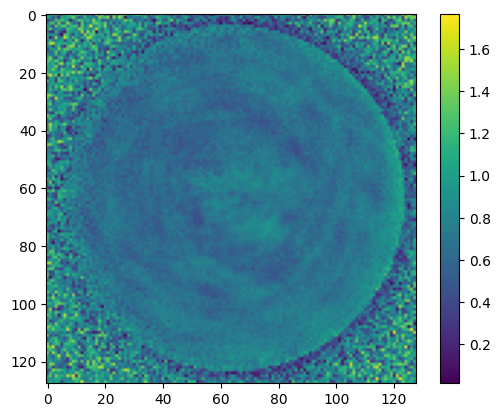

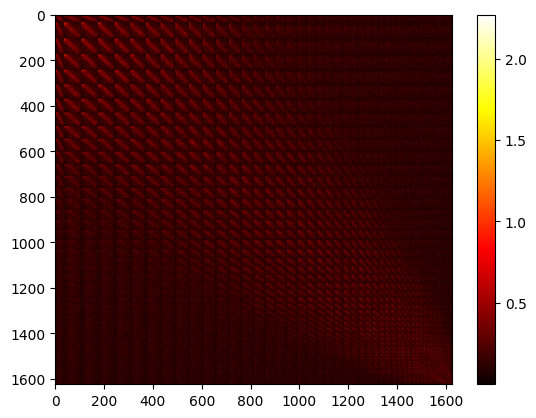

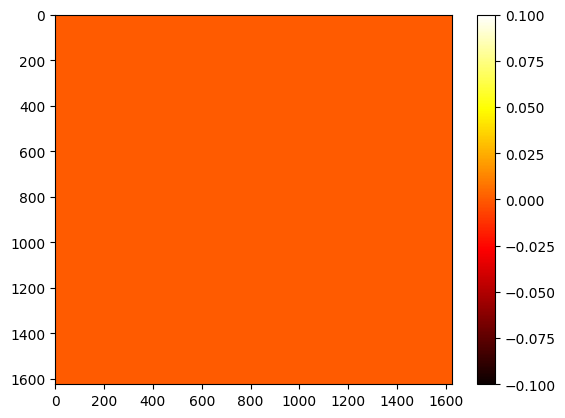

max rel err: 0.0, min rel err: 0.0, avg rel err: 0.0


In [ ]:
amp = tm_system_real.slm_complex_amplitude.detach().cpu().numpy()
print(amp.shape)
plt.figure()
plt.imshow(np.log(1+np.abs(amp)))
plt.colorbar()
plt.show()

TM_abs = tm_system_real.optimized_tm_tensor.abs().detach().cpu().numpy()
plt.figure()
plt.imshow(TM_abs, cmap='hot', aspect='auto')
plt.colorbar()
plt.show()

plt.figure()
plt.imshow(np.abs(TM_abs - TM_abs.T)/(TM_abs+1e-2), cmap='hot', aspect='auto')
plt.colorbar()
plt.show()

rel_err = np.abs(TM_abs - TM_abs.T)#/(TM_abs+1e-2)
print(f"max rel err: {rel_err.max()}, min rel err: {rel_err.min()}, avg rel err: {rel_err.mean()}")


torch.Size([4800, 2, 128, 128])
tensor([63.9824, 63.2741])
tensor([62.6156, 63.5692])


/home/dvir/Desktop/TM_aquisition/.venv/lib/python3.12/site-packages/torch/functional.py:554: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4314.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


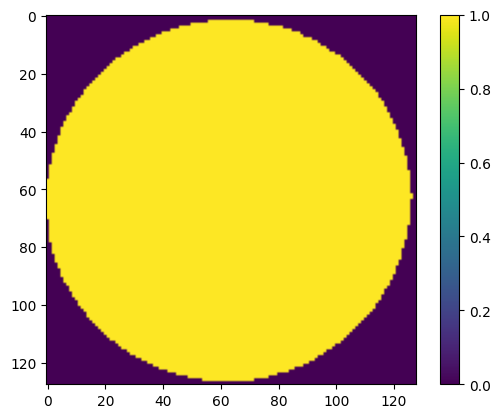

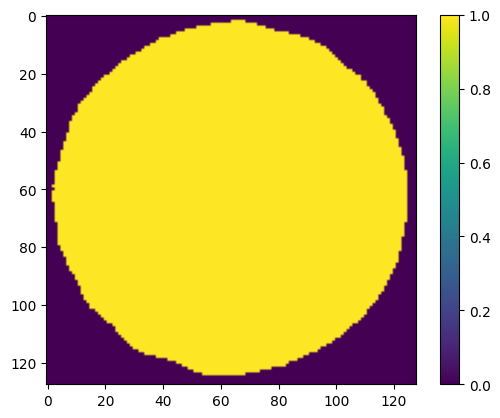

In [ ]:
print(train_data['intensity_targets'].shape)
im_sum = train_data['intensity_targets'].sum(dim=0)
mask = im_sum > 1e4

dens = mask/mask.sum(dim=(1,2),keepdim=True)
x = torch.linspace(0, 127, 128)
X,Y = torch.meshgrid(x,x)
x_0 = (X*dens.cpu()).sum(dim=(1,2))
y_0 = (Y*dens.cpu()).sum(dim=(1,2))
print(x_0)
print(y_0)
plt.figure()
plt.imshow(mask[0].cpu().numpy())
plt.colorbar()
plt.show()
plt.figure()
plt.imshow(mask[1].cpu().numpy())
plt.colorbar()
plt.show()


In [ ]:
dx_cam = 3.45e-6
dx_im = {'tran': dx_cam/50.0, 'ref': dx_cam/50.0}
dx_four = {'tran': dx_cam, 'ref': dx_cam*(250.0/200.0)}
four_range = 1.1*0.22*4e-3
im_range = 1.1*25e-6
dx_SLM = 8e-6*(150.0/400.0)
N_pix = {}
for side in ['tran', 'ref']:
    N_pix[side] = {}
    N_pix[side]['im'] = round(im_range/dx_im[side])
    N_pix[side]['four'] = round(four_range/dx_four[side])
N_pix['SLM'] = 320
dx_final_t = {}
c = 0.47736
for side in ['tran', 'ref']:
    dx_final_t[side] = {}
    dx_final_t[side]['im'] = dx_im[side]*N_pix[side]['im']/64.0
    dx_final_t[side]['four'] = dx_four[side]*N_pix[side]['four']/64.0
dx_final_t['SLM'] = dx_SLM*N_pix['SLM']/64.0
a = train_data['intensity_targets'].sum(dim=(2,3))
b = a[:,0]/a[:,1]*(dx_final_t['tran']['im']*50/dx_final_t['tran']['four'])**2*120.0/150.0*c/(1-c)
print(b.mean()-1.0)
print(1/(1+b.mean()))



tensor(1914.5994, device='cuda:0')
tensor(0.0005, device='cuda:0')


## Fit Mode Distributions to Lab Images

Test whether we can fit mode distributions directly to the lab images (bypassing TM optimization).
This helps determine if the issue is with TM optimization or if the images themselves are not fittable.


In [ ]:
from tqdm import tqdm
def apply_affine_transform(
    intensity: torch.Tensor,
    scale_x: torch.Tensor,
    scale_y: torch.Tensor,
    translate_x: torch.Tensor,
    translate_y: torch.Tensor,
    rotation: torch.Tensor,
    shear_x: torch.Tensor,
    shear_y: torch.Tensor
) -> torch.Tensor:
    """
    Apply affine transformation to intensity images using PyTorch's built-in functions.
    
    Args:
        intensity: (batch, 1, H, W) intensity images
        scale_x, scale_y: scalar scale factors (same for all images)
        translate_x, translate_y: scalar translation in pixels (same for all images)
        rotation: scalar rotation angle in radians (same for all images)
        shear_x, shear_y: scalar shear factors (same for all images)
        
    Returns:
        Transformed intensity: (batch, 1, H, W)
    """
    import torch.nn.functional as F
    
    batch_size, channels, H, W = intensity.shape
    device = intensity.device
    
    # Normalize coordinates to [-1, 1]
    # Translation needs to be normalized by image size
    translate_x_norm = 2.0 * translate_x / W
    translate_y_norm = 2.0 * translate_y / H
    
    # Build affine transformation matrix (same for all images in batch)
    cos_r = torch.cos(rotation)
    sin_r = torch.sin(rotation)
    
    # Combined transformation: scale * rotation * shear
    sx = scale_x
    sy = scale_y
    shx = shear_x
    shy = shear_y
    
    # Combined: scale * rotation * shear
    a = sx * (cos_r - shx * sin_r)
    b = sx * (sin_r + shx * cos_r)
    c = sy * (shy * cos_r - sin_r)
    d = sy * (shy * sin_r + cos_r)
    
    # Affine matrix: [[a, b, tx], [c, d, ty]]
    # Use torch.stack to preserve gradients (don't use torch.tensor which breaks gradients)
    row1 = torch.stack([a, b, translate_x_norm], dim=0)  # (3,)
    row2 = torch.stack([c, d, translate_y_norm], dim=0)  # (3,)
    theta = torch.stack([row1, row2], dim=0)  # (2, 3)
    
    # Expand to batch size (same transformation for all images)
    theta = theta.unsqueeze(0).expand(batch_size, -1, -1)  # (batch, 2, 3)
    
    # Generate grid and apply transformation
    grid = F.affine_grid(theta, intensity.size(), align_corners=False)
    transformed = F.grid_sample(intensity, grid, mode='bilinear', padding_mode='zeros', align_corners=False)
    
    return transformed


def fit_mode_distributions_to_images(
    tm_system: TMMeasurementSystem = None,
    target_intensities: torch.Tensor = None,
    num_images: int = 10,
    num_epochs: int = 200,
    learning_rate: float = 0.01,
    use_zernike_aberrations: bool = True,
    use_exposure_normalization: bool = True
) -> Dict:
    """
    Fit mode distributions directly to target images with optimizable aberrations.
    
    Calculation flow:
    1. From mode distribution calculate the field at the image plane
    2. Calculate the intensity at the image plane and perform affine transformation
    3. ZoomFFT the field and calculate the intensity at the Fourier plane, perform affine transformation to the intensity
    
    Parameters to optimize:
    1. The mode distributions
    2. Zernike coefficients
    3. The perturbed affine coefficients (for intensity transformations)
    
    Args:
        tm_system: TMMeasurementSystem instance
        target_intensities: Target intensities (N, 2, H, W) where [:, 0] = image, [:, 1] = fourier
        num_images: Number of images to fit (uses first N images)
        num_epochs: Number of optimization epochs
        learning_rate: Learning rate for optimizer
        use_zernike_aberrations: If True, optimize Zernike aberrations
        use_exposure_normalization: If True, apply exposure time normalization
        
    Returns:
        Dict containing optimization history and optimized parameters
    """
    print(f"\n{'='*60}")
    print(f"Fitting Mode Distributions to {num_images} Lab Images")
    print(f"{'='*60}")
    if tm_system is None:
        grid_params = {
            'x_range': (-range_im*2, range_im*2),
            'y_range': (-range_im*2, range_im*2),
            'nx': N_0*2,
            'ny': N_0*2
        }
        zoomfft_params = {}
        for side in ['slm', 'tran']:
            zoomfft_params[side] = {
                'a_init': a_param[side],
                'n0_init': (2*N_0 - 1) / 2,
                'm0_init': (2*N_0 - 1) / 2,
                'k0_init': (2*N_0 - 1) / 2,
                'l0_init': (2*N_0 - 1) / 2
            }
        H = 2*N_0
        tm_system = TMMeasurementSystem(
            fiber_params, grid_params, 
            device='cuda', 
            mult_factor=mult_factor,
            zoomfft_params=zoomfft_params,
            zernike_n_modes=8,
            lab_data=False,
            dx=dx_final['tran']
        )
    else:
        H = target_intensities.shape[2]
    # Use first N images
    target_intensities_subset = target_intensities[:num_images]  # (N, 2, H, W)
    N_modes = tm_system.optimized_tm_tensor.shape[0]
    # 1. Initialize mode distributions (complex values)
    # Shape: (N_modes, num_images)
    mode_dists_real = nn.Parameter(torch.randn(N_modes, num_images, device=tm_system.device) * 0.1)
    mode_dists_imag = nn.Parameter(torch.randn(N_modes, num_images, device=tm_system.device) * 0.1)
    
    # Zernike aberration coefficients (initialized to zero = no aberration)
    if use_zernike_aberrations:
        zernike_image = nn.Parameter(torch.zeros(tm_system.zernike_n_modes, device=tm_system.device))
        zernike_fourier = nn.Parameter(torch.zeros(tm_system.zernike_n_modes, device=tm_system.device))
    else:
        zernike_image = torch.zeros(tm_system.zernike_n_modes, device=tm_system.device)
        zernike_fourier = torch.zeros(tm_system.zernike_n_modes, device=tm_system.device)
    
    # Affine transformation parameters for intensities (same for all images)
    # For each plane: scale_x, scale_y, translate_x, translate_y, rotation, shear_x, shear_y
    # Initialize to identity transformation (scale=1, translate=0, rotation=0, shear=0)
    # Note: If exposure normalization is enabled, it applies global scaling which may make
    # affine scale parameters redundant, but translation/rotation/shear should still be learnable
    affine_img_scale_x = nn.Parameter(torch.tensor(1.0, device=tm_system.device))
    affine_img_scale_y = nn.Parameter(torch.tensor(1.0, device=tm_system.device))
    affine_img_translate_x = nn.Parameter(torch.tensor(0.0, device=tm_system.device))
    affine_img_translate_y = nn.Parameter(torch.tensor(0.0, device=tm_system.device))
    affine_img_rotation = nn.Parameter(torch.tensor(0.0, device=tm_system.device), requires_grad=False)
    affine_img_shear_x = nn.Parameter(torch.tensor(0.0, device=tm_system.device))
    affine_img_shear_y = nn.Parameter(torch.tensor(0.0, device=tm_system.device))
    
    affine_fourier_scale_x = nn.Parameter(torch.tensor(1.0, device=tm_system.device))
    affine_fourier_scale_y = nn.Parameter(torch.tensor(1.0, device=tm_system.device))
    affine_fourier_translate_x = nn.Parameter(torch.tensor(0.0, device=tm_system.device))
    affine_fourier_translate_y = nn.Parameter(torch.tensor(0.0, device=tm_system.device))
    affine_fourier_rotation = nn.Parameter(torch.tensor(0.0, device=tm_system.device), requires_grad=False)
    affine_fourier_shear_x = nn.Parameter(torch.tensor(0.0, device=tm_system.device))
    affine_fourier_shear_y = nn.Parameter(torch.tensor(0.0, device=tm_system.device))
    
    im_real_mult = nn.Parameter(torch.ones(H, H, device=tm_system.device))
    im_imag_mult = nn.Parameter(torch.zeros(H, H, device=tm_system.device))
    fourier_real_mult = nn.Parameter(torch.ones(H, H, device=tm_system.device))
    fourier_imag_mult = nn.Parameter(torch.zeros(H, H, device=tm_system.device))
    # Collect all optimizable parameters
    all_params = [mode_dists_real, mode_dists_imag]
    if use_zernike_aberrations:
        all_params += [zernike_image, zernike_fourier]
    all_params += [
        affine_img_scale_x, affine_img_scale_y, affine_img_translate_x, affine_img_translate_y,
        affine_img_rotation, affine_img_shear_x, affine_img_shear_y,
        affine_fourier_scale_x, affine_fourier_scale_y, affine_fourier_translate_x, affine_fourier_translate_y,
        affine_fourier_rotation, affine_fourier_shear_x, affine_fourier_shear_y
    ]
    # all_params += [im_real_mult, im_imag_mult, fourier_real_mult, fourier_imag_mult]
    
    # Setup optimizer
    optimizer = optim.Adam(all_params, lr=learning_rate)
    criterion = nn.L1Loss()
    criterion = PearsonCorrelationLoss(dim=(0,2,3))
    
    # Setup learning rate scheduler: multiply LR by 0.5 every 500 epochs
    scheduler = optim.lr_scheduler.StepLR(
        optimizer, 
        step_size=3000,  # Every 500 epochs
        gamma=0.5  # Multiply LR by 0.5
    )
    
    history = {
        'epoch_losses': [],
        'per_image_losses': [],
        'learning_rates': []
    }
    
    print(f"Optimizing {num_images} mode distributions for {num_epochs} epochs...")
    print(f"Mode distribution shape: ({N_modes}, {num_images})")
    if use_zernike_aberrations:
        print(f"Optimizing Zernike aberrations: Image plane ({tm_system.zernike_n_modes} modes), Fourier plane ({tm_system.zernike_n_modes} modes)")
    else:
        print("Zernike aberrations disabled")
    print("Optimizing affine transformation parameters for image and Fourier plane intensities")
    
    # Initialize progress bar
    pbar = tqdm(range(num_epochs), desc="Training", unit="epoch")
    
    for epoch in pbar:
        optimizer.zero_grad()
        
        # Construct complex mode distributions
        mode_dists = mode_dists_real + 1j * mode_dists_imag  # (N_modes, num_images)
        
        # 1. From mode distribution calculate the field at the image plane
        # This gives us (num_images, 1, 2, H, W) where 1 is plane index (image plane only)
        output_fields = tm_system.calculate_fields_from_mode_dist(mode_dists)
        # output_fields shape: (num_images, 1, 2, H, W)
        E_image_plane = output_fields[:, 0, :, :, :]  # (num_images, 2, H, W)
        # E_image_plane = E_image_plane * (im_real_mult + 1j * im_imag_mult)
        
        # Apply Zernike aberration if enabled
        if use_zernike_aberrations:
            E_image_plane = tm_system.zernike_layer(E_image_plane, zernike_image)
        # 3. ZoomFFT the field and calculate the intensity at the Fourier plane, perform affine transformation
        # Forward transform: image -> Fourier (using default ZoomFFT parameters, not optimized)
        E_fourier = tm_system.zoomfft['tran'](
            E_image_plane, 
            inverse=False
        ) * tm_system.mult_factor['tran']
        E_fourier = E_fourier * (fourier_real_mult + 1j * fourier_imag_mult)
        # Calculate Fourier plane intensity
        I_fourier = torch.abs(E_fourier[:, 0])**2 + torch.abs(E_fourier[:, 1])**2  # (num_images, H, W)
        
        # Apply affine transformation to Fourier plane intensity
        I_fourier_affine = apply_affine_transform(
            I_fourier.unsqueeze(1),  # (num_images, 1, H, W)
            affine_fourier_scale_x, affine_fourier_scale_y,
            affine_fourier_translate_x, affine_fourier_translate_y,
            affine_fourier_rotation, affine_fourier_shear_x, affine_fourier_shear_y
        ).squeeze(1)  # (num_images, H, W)
        I_fourier_affine = I_fourier_affine[:,H//2-64:H//2+64,H//2-64:H//2+64]  # added
        # Apply Zernike aberration in Fourier domain if enabled
        if use_zernike_aberrations:
            E_fourier = tm_system.zernike_layer(E_fourier, zernike_fourier)
        E_image_plane = tm_system.zoomfft['tran'](
            E_fourier, 
            inverse=True
        ) / tm_system.mult_factor['tran']

        # 2. Calculate the intensity at the image plane and perform affine transformation
        I_image = torch.abs(E_image_plane[:, 0])**2 + torch.abs(E_image_plane[:, 1])**2  # (num_images, H, W)
        
        # Apply affine transformation to image plane intensity
        I_image_affine = apply_affine_transform(
            I_image.unsqueeze(1),  # (num_images, 1, H, W)
            affine_img_scale_x, affine_img_scale_y,
            affine_img_translate_x, affine_img_translate_y,
            affine_img_rotation, affine_img_shear_x, affine_img_shear_y
        ).squeeze(1)  # (num_images, H, W)
        I_image_affine = I_image_affine[:,H//2-64:H//2+64,H//2-64:H//2+64]  # added
        
        # Combine intensities: (num_images, 2, H, W)
        pred_intensities = torch.stack([I_image_affine, I_fourier_affine], dim=1)
        
        # Apply exposure normalization if enabled
        if use_exposure_normalization:
            # Image plane normalization
            pred_img = pred_intensities[:, 0:1]  # (num_images, 1, H, W)
            target_img = target_intensities_subset[:, 0:1]  # (num_images, 1, H, W)
            numerator_img = torch.sum(pred_img * target_img)
            denominator_img = torch.sum(pred_img ** 2)
            scale_img = (numerator_img / (denominator_img)).detach()
            
            # Fourier plane normalization
            pred_fourier = pred_intensities[:, 1:2]
            target_fourier = target_intensities_subset[:, 1:2]
            numerator_fourier = torch.sum(pred_fourier * target_fourier)
            denominator_fourier = torch.sum(pred_fourier ** 2)
            scale_fourier = (numerator_fourier / (denominator_fourier)).detach()
            
            pred_normalized = torch.cat([pred_img * scale_img, pred_fourier * scale_fourier], dim=1)
        else:
            pred_normalized = pred_intensities
        
        # 7. Calculate the loss between the lab and the calculated intensities, backpropagate and take step
        # Loss (Amplitude)
        # pred_amp = torch.sqrt(pred_normalized)
        # target_amp = torch.sqrt(target_intensities_subset)
        # norm_factor = torch.mean(target_amp).detach()
        pred_amp = pred_normalized
        target_amp = target_intensities_subset
        norm_factor = torch.mean(target_amp).detach()
        norm_factor = 1.0
        # Calculate separate losses for image and Fourier planes (as tensors for gradient flow)
        # Image plane loss
        pred_amp_img = pred_amp[:, 0:1] / norm_factor
        target_amp_img = target_amp[:, 0:1] / norm_factor
        loss_img_tensor = criterion(pred_amp_img, target_amp_img)
        
        # Fourier plane loss
        pred_amp_fourier = pred_amp[:, 1:2] / norm_factor
        target_amp_fourier = target_amp[:, 1:2] / norm_factor
        loss_fourier_tensor = criterion(pred_amp_fourier, target_amp_fourier)
        
        # Calculate ratio of losses (with no grad) to balance them
        with torch.no_grad():
            loss_img_val = loss_img_tensor.item()
            loss_fourier_val = loss_fourier_tensor.item()
            # Calculate ratio: image_loss / fourier_loss
            if loss_fourier_val > 1e-8:
                loss_ratio = loss_img_val / loss_fourier_val
            else:
                loss_ratio = 1.0
        loss_ratio = 1.0
        # Total loss: image_loss + factor * fourier_loss, where factor balances them
        # If image_loss is much bigger, we scale fourier_loss up by the ratio
        # This makes them contribute equally: image_loss = factor * fourier_loss
        # So factor = image_loss / fourier_loss = loss_ratio
        total_loss = loss_img_tensor + loss_ratio * loss_fourier_tensor
        
        # Backward
        total_loss.backward()
        optimizer.step()
        
        # Track losses
        epoch_loss = total_loss.item()
        history['epoch_losses'].append(epoch_loss)
        
        # Calculate per-image losses
        with torch.no_grad():
            per_image_losses = []
            for i in range(num_images):
                pred_i = pred_amp[i:i+1] / norm_factor
                target_i = target_amp[i:i+1] / norm_factor
                loss_i = criterion(pred_i, target_i).item()
                per_image_losses.append(loss_i)
            history['per_image_losses'].append(per_image_losses)
        
        # Update learning rate scheduler (multiplies LR by 0.5 every 500 epochs)
        scheduler.step()
        
        # Track current learning rate
        current_lr = optimizer.param_groups[0]['lr']
        history['learning_rates'].append(current_lr)
        
        # Update progress bar with loss information
        avg_per_image = np.mean(per_image_losses)
        pbar.set_postfix({
            'Total': f'{epoch_loss:.6f}',
            'Img': f'{loss_img_val:.6f}',
            'Fourier': f'{loss_fourier_val:.6f}',
            'Ratio': f'{loss_ratio:.4f}',
            'LR': f'{current_lr:.2e}',
            'Avg/img': f'{avg_per_image:.6f}'
        })
    
    # Get final optimized parameters
    final_mode_dists = (mode_dists_real + 1j * mode_dists_imag).detach()
    if use_zernike_aberrations:
        final_zernike_image = zernike_image.detach()
        final_zernike_fourier = zernike_fourier.detach()
    else:
        final_zernike_image = None
        final_zernike_fourier = None
    
    # Final affine parameters (scalars)
    final_affine_img = {
        'scale_x': affine_img_scale_x.detach().item(),
        'scale_y': affine_img_scale_y.detach().item(),
        'translate_x': affine_img_translate_x.detach().item(),
        'translate_y': affine_img_translate_y.detach().item(),
        'rotation': affine_img_rotation.detach().item(),
        'shear_x': affine_img_shear_x.detach().item(),
        'shear_y': affine_img_shear_y.detach().item()
    }
    final_affine_fourier = {
        'scale_x': affine_fourier_scale_x.detach().item(),
        'scale_y': affine_fourier_scale_y.detach().item(),
        'translate_x': affine_fourier_translate_x.detach().item(),
        'translate_y': affine_fourier_translate_y.detach().item(),
        'rotation': affine_fourier_rotation.detach().item(),
        'shear_x': affine_fourier_shear_x.detach().item(),
        'shear_y': affine_fourier_shear_y.detach().item()
    }
    
    print(f"\nOptimization complete!")
    print(f"Final loss: {history['epoch_losses'][-1]:.6f}")
    print(f"Final per-image losses: {[f'{l:.6f}' for l in history['per_image_losses'][-1][:10]]}..." if num_images > 10 else f"Final per-image losses: {[f'{l:.6f}' for l in history['per_image_losses'][-1]]}")
    
    # Print final affine transformation parameters
    print(f"\n{'='*60}")
    print("Final Optimized Affine Transformation Parameters")
    print(f"{'='*60}")
    print("Image Plane:")
    for key, value in final_affine_img.items():
        print(f"  {key}: {value:.6f}")
    print("\nFourier Plane:")
    for key, value in final_affine_fourier.items():
        print(f"  {key}: {value:.6f}")
    
    # Print final Zernike coefficients if they were optimized
    if use_zernike_aberrations and final_zernike_image is not None and final_zernike_fourier is not None:
        print(f"\n{'='*60}")
        print("Final Optimized Zernike Coefficients")
        print(f"{'='*60}")
        print("Image Plane:")
        zernike_img_np = final_zernike_image.cpu().numpy()
        for i, coeff in enumerate(zernike_img_np):
            print(f"  Mode {i+1}: {coeff:.6f}")
        print("\nFourier Plane:")
        zernike_fourier_np = final_zernike_fourier.cpu().numpy()
        for i, coeff in enumerate(zernike_fourier_np):
            print(f"  Mode {i+1}: {coeff:.6f}")
        # Also print summary statistics
        print(f"\nImage Plane Zernike - Mean: {zernike_img_np.mean():.6f}, Std: {zernike_img_np.std():.6f}, Max: {zernike_img_np.max():.6f}, Min: {zernike_img_np.min():.6f}")
        print(f"Fourier Plane Zernike - Mean: {zernike_fourier_np.mean():.6f}, Std: {zernike_fourier_np.std():.6f}, Max: {zernike_fourier_np.max():.6f}, Min: {zernike_fourier_np.min():.6f}")
    
    return {
        'history': history,
        'optimized_mode_dists': final_mode_dists,
        'optimized_affine_img': final_affine_img,
        'optimized_affine_fourier': final_affine_fourier,
        'optimized_zernike_image': final_zernike_image,
        'optimized_zernike_fourier': final_zernike_fourier,
        'final_pred_intensities': pred_normalized.detach()
    }

In [ ]:
from metrics_losses import PearsonCorrelationLoss
def fit_mode_distributions_to_images_zoomfft(
    tm_system: TMMeasurementSystem,
    target_intensities: torch.Tensor,
    num_images: int = 10,
    num_epochs: int = 200,
    learning_rate: float = 0.01,
    use_zernike_aberrations: bool = True,
    use_exposure_normalization: bool = True
) -> Dict:
    """
    Fit mode distributions directly to target images, optimizing ZoomFFT parameters
    (instead of affine intensity transforms) along with optional Zernike aberrations.
    """
    print(f"\n{'='*60}")
    print(f"Fitting Mode Distributions (ZoomFFT) to {num_images} Lab Images")
    print(f"{'='*60}")

    H = target_intensities.shape[2]
    target_intensities_subset = target_intensities[:num_images]
    N_modes = tm_system.optimized_tm.shape[0]

    # Mode distributions (complex)
    mode_dists_real = nn.Parameter(torch.randn(N_modes, num_images, device=tm_system.device) * 0.1)
    mode_dists_imag = nn.Parameter(torch.randn(N_modes, num_images, device=tm_system.device) * 0.1)

    # Zernike aberrations
    if use_zernike_aberrations:
        zernike_image = nn.Parameter(torch.zeros(tm_system.zernike_n_modes, device=tm_system.device))
        zernike_fourier = nn.Parameter(torch.zeros(tm_system.zernike_n_modes, device=tm_system.device))
    else:
        zernike_image = torch.zeros(tm_system.zernike_n_modes, device=tm_system.device)
        zernike_fourier = torch.zeros(tm_system.zernike_n_modes, device=tm_system.device)

    # Parameters to optimize: mode dists, zernike (optional), ZoomFFT params
    all_params = [mode_dists_real, mode_dists_imag]
    if use_zernike_aberrations:
        all_params += [zernike_image, zernike_fourier]
    for pd in [tm_system.zoomfft_slm_params, tm_system.zoomfft_out_fwd_params, tm_system.zoomfft_out_inv_params]:
        all_params += list(pd.values())

    optimizer = optim.Adam(all_params, lr=learning_rate)
    criterion = PearsonCorrelationLoss(dim=(0,2,3), center=False)

    history = {'epoch_losses': [], 'per_image_losses': [], 'learning_rates': []}
    pbar = tqdm(range(num_epochs), desc="Training", unit="epoch")

    for epoch in pbar:
        optimizer.zero_grad()

        mode_dists = mode_dists_real + 1j * mode_dists_imag  # (N_modes, num_images)
        output_fields = tm_system.calculate_fields_from_mode_dist(mode_dists)
        E_image_plane = output_fields[:, 0, :, :, :]  # (num_images, 2, H, W)

        if use_zernike_aberrations:
            E_image_plane = tm_system.zernike_layer(E_image_plane, zernike_image)

        # Forward ZoomFFT (image -> Fourier) using learnable params
        z_fwd = tm_system._get_zoomfft_params_dict(tm_system.zoomfft_out_fwd_params)
        E_fourier = tm_system.zoomfft['tran'](E_image_plane, inverse=False, **z_fwd) * tm_system.mult_factor['tran']

        if use_zernike_aberrations:
            E_fourier = tm_system.zernike_layer(E_fourier, zernike_fourier)

        # Inverse ZoomFFT (Fourier -> image) using learnable params
        z_inv = tm_system._get_zoomfft_params_dict(tm_system.zoomfft_out_inv_params)
        E_image_plane = tm_system.zoomfft['tran'](E_fourier, inverse=True, **z_inv) / tm_system.mult_factor['tran']

        I_fourier = torch.abs(E_fourier[:, 0])**2 + torch.abs(E_fourier[:, 1])**2
        I_image = torch.abs(E_image_plane[:, 0])**2 + torch.abs(E_image_plane[:, 1])**2

        # Optional center crop to 128x128 if larger
        c = H // 2
        I_fourier_c = I_fourier[:, c-64:c+64, c-64:c+64]
        I_image_c = I_image[:, c-64:c+64, c-64:c+64]

        pred_intensities = torch.stack([I_image_c, I_fourier_c], dim=1)

        # Exposure normalization (per plane)
        if use_exposure_normalization:
            pred_img = pred_intensities[:, 0:1]
            target_img = target_intensities_subset[:, 0:1]
            numerator_img = torch.sum(pred_img * target_img)
            denominator_img = torch.sum(pred_img ** 2) + 1e-10
            scale_img = (numerator_img / denominator_img).detach()

            pred_fourier = pred_intensities[:, 1:2]
            target_fourier = target_intensities_subset[:, 1:2]
            numerator_fourier = torch.sum(pred_fourier * target_fourier)
            denominator_fourier = torch.sum(pred_fourier ** 2) + 1e-10
            scale_fourier = (numerator_fourier / denominator_fourier).detach()

            pred_normalized = torch.cat([pred_img * scale_img, pred_fourier * scale_fourier], dim=1)
        else:
            pred_normalized = pred_intensities

        pred_amp = pred_normalized
        target_amp = target_intensities_subset
        norm_factor = torch.mean(target_amp).detach()
        norm_factor = 1.0

        pred_amp_img = pred_amp[:, 0:1] / norm_factor
        target_amp_img = target_amp[:, 0:1] / norm_factor
        loss_img_tensor = criterion(pred_amp_img, target_amp_img)

        pred_amp_fourier = pred_amp[:, 1:2] / norm_factor
        target_amp_fourier = target_amp[:, 1:2] / norm_factor
        loss_fourier_tensor = criterion(pred_amp_fourier, target_amp_fourier)

        loss_ratio = 1.0
        total_loss = loss_img_tensor + loss_ratio * loss_fourier_tensor

        total_loss.backward()
        optimizer.step()

        epoch_loss = total_loss.item()
        history['epoch_losses'].append(epoch_loss)
        with torch.no_grad():
            per_image_losses = []
            for i in range(num_images):
                pred_i = pred_amp[i:i+1] / norm_factor
                target_i = target_amp[i:i+1] / norm_factor
                loss_i = criterion(pred_i, target_i).item()
                per_image_losses.append(loss_i)
            history['per_image_losses'].append(per_image_losses)
        current_lr = optimizer.param_groups[0]['lr']
        history['learning_rates'].append(current_lr)
        pbar.set_postfix({'Total': f'{epoch_loss:.6f}', 'Img': f'{loss_img_tensor.item():.6f}', 'Fourier': f'{loss_fourier_tensor.item():.6f}', 'LR': f'{current_lr:.2e}'})

    print(f"\nOptimization complete! Final loss: {history['epoch_losses'][-1]:.6f}")
    print(f"final forward parameters:")
    for key, value in tm_system.zoomfft_out_fwd_params.items():
        print(f"  {key}: {value.item()}")
    print(f"final inverse parameters:")
    for key, value in tm_system.zoomfft_out_inv_params.items():
        print(f"  {key}: {value.item()}")
    return {
        'history': history,
        'optimized_mode_dists': (mode_dists_real + 1j * mode_dists_imag).detach(),
        'optimized_zernike_image': zernike_image.detach() if use_zernike_aberrations else None,
        'optimized_zernike_fourier': zernike_fourier.detach() if use_zernike_aberrations else None,
        'final_pred_intensities': pred_normalized.detach()
    }

In [ ]:
# Fit mode distributions to first N images from training set
N_images_to_fit = 100  # Adjust as needed

mode_dist_list = []
corr_list = []
for i in range(4):
    print(f"\nFitting mode distributions to first {N_images_to_fit} images from training set...")
    mode_fit_results = fit_mode_distributions_to_images_zoomfft(
        tm_system=tm_system_real,
        target_intensities=train_data['intensity_targets'],
        num_images=N_images_to_fit,
        num_epochs=2000,
        learning_rate=0.001,
        use_zernike_aberrations=False,  # Optimize Zernike aberrations
        use_exposure_normalization=False
    )
    mode_dist_results = mode_fit_results['optimized_mode_dists'].cpu().numpy()
    norm_factor = np.sqrt(np.sum(np.abs(mode_dist_results)**2, axis=0, keepdims=True))
    mode_dist_normalized = mode_dist_results / (norm_factor)

    for mode_dist in mode_dist_list:
        overlap = np.abs(np.sum(mode_dist_normalized * np.conj(mode_dist), axis=0))
        corr_list.append(np.mean(overlap))
    mode_dist_list.append(mode_dist_normalized)
print(f"Correlation list: {corr_list}")



# Plot training history
plt.figure(figsize=(10, 6))
plt.plot(mode_fit_results['history']['epoch_losses'], label='Total Loss', linewidth=2)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.title('Mode Distribution Fitting: Training Loss', fontsize=14)
plt.legend(fontsize=12)
plt.grid(True, alpha=0.3)
plt.yscale('log')
plt.tight_layout()
plt.show()

# Visualize a few examples
num_examples_to_show = min(1, N_images_to_fit)

for idx in range(num_examples_to_show):
    pred = mode_fit_results['final_pred_intensities'][idx].detach().cpu().numpy()
    target = train_data['intensity_targets'][idx].detach().cpu().numpy()
    
    # Image plane figure
    fig_img, axes_img = plt.subplots(1, 2, figsize=(12, 6), dpi=800)
    fig_img.suptitle(f'Mode Distribution Fitting: Image Plane - Image {idx+1}', fontsize=16, fontweight='bold')
    
    axes_img[0].imshow(np.round((target[0]-np.min(target[0]))/(np.max(target[0])-np.min(target[0]))*255), cmap='hot', aspect='auto')
    axes_img[0].set_title(f'Target (Image) - Image {idx+1}', fontsize=12)
    axes_img[0].axis('off')

    axes_img[1].imshow(np.round((pred[0]-np.min(pred[0]))/(np.max(pred[0])-np.min(pred[0]))*255), cmap='hot', aspect='auto')
    axes_img[1].set_title(f'Predicted (Image) - Image {idx+1}', fontsize=12)
    axes_img[1].axis('off')

    plt.tight_layout()
    plt.show()

    # Fourier plane figure
    fig_fourier, axes_fourier = plt.subplots(1, 2, figsize=(12, 6), dpi=800)
    fig_fourier.suptitle(f'Mode Distribution Fitting: Fourier Plane - Image {idx+1}', fontsize=16, fontweight='bold')
    
    axes_fourier[0].imshow(np.round((target[1]-np.min(target[1]))/(np.max(target[1])-np.min(target[1]))*255), cmap='hot', aspect='auto')
    axes_fourier[0].set_title(f'Target (Fourier) - Image {idx+1}', fontsize=12)
    axes_fourier[0].axis('off')

    axes_fourier[1].imshow(np.round((pred[1]-np.min(pred[1]))/(np.max(pred[1])-np.min(pred[1]))*255), cmap='hot', aspect='auto')
    axes_fourier[1].set_title(f'Predicted (Fourier) - Image {idx+1}', fontsize=12)
    axes_fourier[1].axis('off')

    plt.tight_layout()
    plt.show()

print("\n" + "="*60)
print("Mode Distribution Fitting Summary")
print("="*60)
print(f"Final total loss: {mode_fit_results['history']['epoch_losses'][-1]:.6f}")
print(f"Average final per-image loss: {np.mean(mode_fit_results['history']['per_image_losses'][-1]):.6f}")
print(f"Min final per-image loss: {np.min(mode_fit_results['history']['per_image_losses'][-1]):.6f}")
print(f"Max final per-image loss: {np.max(mode_fit_results['history']['per_image_losses'][-1]):.6f}")
print("\nIf losses are low, mode distributions can fit the images.")
print("If losses remain high, the images may not be fittable with this model.")


Fitting mode distributions to first 100 images from training set...

Fitting Mode Distributions (ZoomFFT) to 100 Lab Images


Training:  70%|██████▉   | 1395/2000 [00:54<00:23, 25.64epoch/s, Total=0.022076, Img=0.010112, Fourier=0.011965, LR=1.00e-03]